# NSD fMRI 전처리와 이미지·캡션 연결

NSD 피험자 한 명의 원시 BOLD 영상에서 이미지별 β-map을 추출하고, 자극 이미지 ID를 통해 COCO 캡션과 연결하는 과정을 정리했다. HCP 전처리에서 작성한 보정 함수를 재사용하되, GLM의 조건을 인지 과제명이 아닌 이미지 ID로 구성한다.

## 프로젝트 안에서의 역할

| 단계 | 내용 |
|---|---|
| 01 · HCP preprocessing | 조건별 β-map 추출과 공통 전처리 함수 작성 |
| **02 · NSD preprocessing — 현재 문서** | NSD 영상 처리, 이미지 ID별 β-map 추출, 캡션 연결 |
| 03 · HCP classification | 별도 제공 β-map으로 분류 인코더 학습 |
| 04 · NSD caption decoding | 별도 제공 NSD β-map으로 캡션 생성 학습 |

여기서 추출한 데이터는 캡션 모델의 주 학습 데이터가 아니다. 모델 학습은 별도 제공 데이터로 진행했으며, 이 산출물은 학습 후 추가 입력 테스트에 사용했다.

## 실행 전 확인

- 원시 NSD 데이터, COCO 캡션 JSON, `nsd_stim_info_merged.csv`가 필요하다. 코드의 로컬 경로는 데이터 위치에 맞게 바꿔야 한다.
- `slice_timing_correct_4d`, `ants_rigid_motion_correction`, `compute_fd_from_motion`은 01 노트북에서 정의한 함수다. 현재 파일에서 다시 정의하지 않으므로 실행 환경에 먼저 준비해야 한다.
- 아래 결과는 기존 실행 기록이며, 문서 정리 과정에서 전처리를 재실행하지 않았다.
- 설치·import 셀에는 프로젝트 전체에서 공유하던 라이브러리도 포함되어 있다.


In [1]:
!pip install nilearn nibabel
!pip install antspyx
!pip install transformers evaluate rouge_score h5py


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 73.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.4/22.4 MB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 12.6 MB/s eta 0:00:00
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.3 MB/s eta 0:00:00
  Created wheel for rouge_score: filename=rouge_score-0.1.2-py3-none-any.whl size=24934 sha256=41ef39ddb0b2ff9dfbf3ca9807a7fb7c26ca1e2bde9ea34bf9d8114e7cb46715
  Stored in directory: /root/.cache/pip/wheels/85/9d/af/01feefbe7d55ef5468796f0c68225b6788e85d9d0a281e7a70
Successfully built rouge_score


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path
import importlib.util
import nibabel as nib
from nilearn import image, plotting
from nilearn import datasets
from nilearn.maskers import NiftiMasker
from nilearn.glm.first_level import (
        FirstLevelModel,
        make_first_level_design_matrix,
    )
from nilearn.masking import apply_mask
from sklearn.model_selection import train_test_split
from scipy.spatial.transform import Rotation
import ants
import random
import json

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.manifold import TSNE
from transformers import AutoTokenizer, AutoModelForCausalLM
import evaluate
import h5py
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from rouge_score import rouge_scorer


## 1. 입력 데이터와 ID 연결

대상 피험자는 `sub-01`이다. 각 run의 기능영상 폴더에서 다음 세 종류를 읽는다.

| 파일 | 사용 정보 |
|---|---|
| `*_bold.nii.gz` | 4D BOLD 시계열 |
| `*_bold.json` | slice acquisition timing 등 메타데이터 |
| `*_events.tsv` | 자극 ID, onset, duration |

자극 정보 CSV와 COCO annotation을 연결하는 경로는 다음과 같다.

```text
이벤트의 73k_id → CSV의 nsdId → cocoId → COCO 캡션 목록
```

한 이미지에는 여러 캡션이 연결된다. COCO의 `train2017`·`val2017` 캡션 파일은 합쳐 사용하며, 이 구분을 이후 fMRI 모델의 train/validation 분할로 사용하지는 않는다.


## 2. 처리 흐름과 결과 요약

```text
BOLD 영상 + JSON + events TSV
 → 이미지 ID와 자극 시점 연결
 → 시간 보정·움직임 보정·공간 평활화
 → run별 GLM (trial_type = cocoId)
 → 이미지 ID별 β-map 추출
 → β-map과 cocoId 저장
```

| 항목 | 기존 실행 기록 |
|---|---|
| 피험자 | `sub-01` |
| 처리 run 수 | 15 |
| 영상 크기 | `(120, 120, 84, 188)` |
| TR | 1.6초 |
| 공간 평활화 | FWHM 6 mm |
| 집계 β-map 배열 | `(133, 292796)` |

메모리 사용량을 제한하기 위해 일부 세션과 파일만 읽었다. 구조영상과의 coregistration 및 표준공간 정규화는 생략했고, MNI152 brain mask를 영상 격자로 resampling해 사용했다. 이는 표준공간 정합을 완료한 데이터와는 구분된다.


In [ ]:


def load_caption_dict(anno_path):
    with open(anno_path, 'r') as f:
        coco = json.load(f)

    cap_dict = {}
    for ann in coco['annotations']:
        img_id = ann['image_id']
        if img_id not in cap_dict:
            cap_dict[img_id] = []
        cap_dict[img_id].append(ann['caption'])
    return cap_dict

def load_coco_id(df_sub, tsv) :
    cocoId_list = []

    for index, row in tsv.iterrows():
        current_73k_id = int(row['73k_id'])
        if not current_73k_id in df_sub['nsdId'].values :
            continue

        cocoId = df_sub[df_sub['nsdId'] == current_73k_id]['cocoId'].values[0]

        cocoId_list.append({
            "onset": row['onset'],
            "duration": row['duration'],
            "trial_type": f"{cocoId}"
        })

    return pd.DataFrame(cocoId_list)

def preprocess_image(func_raw_img, FUNC_JSON) :
    tr = func_raw_img.header.get_zooms()[-1]

    func_raw_data = func_raw_img.get_fdata(dtype=np.float32)
    slice_timing = FUNC_JSON.get("SliceTiming", None)
    corrected_data = slice_timing_correct_4d(func_raw_data, tr, slice_timing=slice_timing)

    mc_data, motion_df, motion_method = ants_rigid_motion_correction(corrected_data, func_raw_img.affine)
    motion_df["framewise_displacement"] = compute_fd_from_motion(motion_df)
    func_mc_img = nib.Nifti1Image(mc_data, func_raw_img.affine, func_raw_img.header)

    smooth_source = func_mc_img
    smooth_img = image.smooth_img(smooth_source, fwhm=SMOOTH_FWHM)

    result = smooth_img

    n_frames = result.shape[3]

    print("Image shape:", result.shape)
    print("TR:", tr)
    return result


### 2.1 캡션 사전과 이벤트 테이블 구성

- **`load_caption_dict`**: COCO annotation의 `image_id`를 key로, 해당 이미지의 캡션 목록을 value로 묶는다. 이 key는 NSD의 `nsdId`가 아니라 COCO 이미지 ID다.
- **`load_coco_id`**: 이벤트의 `73k_id`를 CSV의 `nsdId`와 대조해 `cocoId`를 찾고, GLM용 `onset`, `duration`, `trial_type` 테이블을 만든다.
- **`preprocess_image`**: NIfTI 헤더에서 TR을 읽은 뒤 시간 보정, rigid-body 움직임 보정, FWHM 6 mm 평활화를 적용한다.

움직임 파라미터와 FD도 계산하지만, 현재 코드에서는 GLM confound로 전달하거나 별도 산출물로 저장하지 않는다.


In [ ]:
sub_id_int = 1
sub_id = "01"

max_session = 4
max_file = 5

captions_data = "C:/Users/KRAFTON/Downloads/minsungg/nsd-stimuli-captions"
nsd_exp_dir = f"{captions_data}/nsddata/experiments/nsd"
csv_file = f"{nsd_exp_dir}/nsd_stim_info_merged.csv"

jsons = []
imgs = []
tsvs = []

for idx, ses_nsd0n in enumerate(os.listdir(f"C:/Users/KRAFTON/Downloads/minsungg/NSD_data/sub-{sub_id}")):
    if idx >= max_session :
        break
    if ses_nsd0n == "ses-nsdanat" or ses_nsd0n == "preprocessed":
        continue

    for idx_, nsd_file in enumerate(os.listdir(f"C:/Users/KRAFTON/Downloads/minsungg/NSD_data/sub-{sub_id}/{ses_nsd0n}/func")):
        if idx_ >= 5 * max_file :
            break

        if nsd_file.endswith('bold.json') :
            with open(f"C:/Users/KRAFTON/Downloads/minsungg/NSD_data/sub-{sub_id}/{ses_nsd0n}/func/{nsd_file}", "r", encoding="utf-8") as f:
                json_file = json.load(f)
                jsons.append(json_file)
        elif nsd_file.endswith('bold.nii.gz') :
            img = nib.load(f"C:/Users/KRAFTON/Downloads/minsungg/NSD_data/sub-{sub_id}/{ses_nsd0n}/func/{nsd_file}")
            imgs.append(img)
        elif nsd_file.endswith('events.tsv') :
            tsv = pd.read_csv(f"C:/Users/KRAFTON/Downloads/minsungg/NSD_data/sub-{sub_id}/{ses_nsd0n}/func/{nsd_file}", sep='\t')
            tsvs.append(tsv)

captions_dict_train = load_caption_dict(f"{captions_data}/annotations/captions_train2017.json")
captions_dict_val = load_caption_dict(f"{captions_data}/annotations/captions_val2017.json")
all_captions = {**captions_dict_train, **captions_dict_val}

df = pd.read_csv(csv_file)

df_sub1 = df[df[f'subject{sub_id_int}'] > 0].copy()
df_sub1['captions'] = df_sub1['cocoId'].apply(lambda x: all_captions.get(x, ["No caption available"]))


### 2.2 일부 세션 로딩과 캡션 매핑

피험자 번호는 정수 `1`과 경로용 문자열 `01`로 구분한다. 입력 크기를 제한하는 설정은 `max_session=4`, `max_file=5`다.

이 제한은 디렉터리 순회 인덱스에 적용된다. 제외 폴더도 인덱스에 포함될 수 있고, 세션 안에서는 파일 인덱스 `5 × max_file`을 경계로 삼는다. 따라서 설정값 자체를 실제 처리 세션·run 수로 읽기보다는 아래 실행 출력을 확인해야 한다. `os.listdir` 결과를 정렬하지 않으므로 선택되는 부분집합도 폴더 순서에 영향을 받는다.

캡션은 두 annotation 파일을 합친 뒤 CSV에서 대상 피험자에게 제시된 이미지로 범위를 좁혀 연결한다. `df_sub1['captions']`에 캡션 목록을 보관하고, 영상·메타데이터·이벤트는 각 리스트에 적재한다. 파일을 독립적으로 수집하는 구조이므로 재실행 시에는 세 리스트의 run 대응도 확인해야 한다.


In [ ]:

SMOOTH_FWHM = 6.0

preprocessed_imgs = []
coco_ids = []

for i in range(len(tsvs)) :
    coco_ids.append(load_coco_id(df_sub1, tsvs[i]))
    preprocessed_imgs.append(preprocess_image(imgs[i], jsons[i]))

mni_mask = datasets.load_mni152_brain_mask()
resampled_mask = image.resample_to_img(mni_mask, preprocessed_imgs[0], interpolation='nearest')

beta_map_datas = []
new_coco_ids = []

for i in range(len(preprocessed_imgs)):
    first_level_model = FirstLevelModel(
        t_r=1.6,
        mask_img=resampled_mask,
        hrf_model="glover",
        drift_model="cosine",
        high_pass=0.005,
        smoothing_fwhm=None,
        noise_model="ar1",
        standardize='zscore_sample',
        minimize_memory=True,
    )
    first_level_model.fit(preprocessed_imgs[i], events=coco_ids[i])

    current_cocoIds = []
    for coco_id in coco_ids[i]['trial_type']:
        if coco_id not in current_cocoIds:
            current_cocoIds.append(coco_id)

    design_columns = first_level_model.design_matrices_[0].columns.tolist()

    for coco_id in current_cocoIds:
        beta_map_3d = first_level_model.compute_contrast(coco_id, output_type='effect_size')
        beta_map_1d = apply_mask(beta_map_3d, resampled_mask)

        beta_map_datas.append(beta_map_1d)
        new_coco_ids.append(coco_id)


Image shape: (120, 120, 84, 188)
TR: 1.6
Image shape: (120, 120, 84, 188)
TR: 1.6
Image shape: (120, 120, 84, 188)
TR: 1.6
Image shape: (120, 120, 84, 188)
TR: 1.6
Image shape: (120, 120, 84, 188)
TR: 1.6
Image shape: (120, 120, 84, 188)
TR: 1.6
Image shape: (120, 120, 84, 188)
TR: 1.6
Image shape: (120, 120, 84, 188)
TR: 1.6
Image shape: (120, 120, 84, 188)
TR: 1.6
Image shape: (120, 120, 84, 188)
TR: 1.6
Image shape: (120, 120, 84, 188)
TR: 1.6
Image shape: (120, 120, 84, 188)
TR: 1.6
Image shape: (120, 120, 84, 188)
TR: 1.6
Image shape: (120, 120, 84, 188)
TR: 1.6
Image shape: (120, 120, 84, 188)
TR: 1.6


C:\Users\KRAFTON\AppData\Local\Temp\ipykernel_1064\2125376812.py:29: UserWarning: imgs are being resampled to the mask_img resolution. This process is memory intensive. You might want to provide a target_affine that is equal to the affine of the imgs or resample the mask beforehand to save memory and computation time.
  first_level_model.fit(preprocessed_imgs[i], events=coco_ids[i])
C:\Users\KRAFTON\AppData\Local\Temp\ipykernel_1064\2125376812.py:29: UserWarning: Mean values of 0 observed. The data have probably been centered. Scaling might not work as expected.
  first_level_model.fit(preprocessed_imgs[i], events=coco_ids[i])
C:\Users\KRAFTON\AppData\Local\Temp\ipykernel_1064\2125376812.py:29: UserWarning: imgs are being resampled to the mask_img resolution. This process is memory intensive. You might want to provide a target_affine that is equal to the affine of the imgs or resample the mask beforehand to save memory and computation time.
  first_level_model.fit(preprocessed_imgs[i],

## 3. 이미지 ID별 GLM과 β-map 추출

HCP에서는 과제 조건명을 회귀변수로 사용했다면, 여기서는 **이미지의 `cocoId`**를 사용한다. 캡션 문구를 조건명으로 쓰지 않고 이미지 ID를 고정 key로 두어, 같은 이미지가 서로 다른 캡션 때문에 다른 조건으로 나뉘지 않도록 했다.

GLM 설정은 `glover` HRF, cosine drift, high-pass 0.005 Hz, AR(1) noise model이며, TR은 1.6초다. 평활화는 앞에서 수행했으므로 GLM 내부 smoothing은 적용하지 않는다.

각 run에서 고유한 이미지 ID를 모아 `effect_size` map을 추출한다. **같은 run에 동일 이미지가 반복되면 하나의 회귀변수로 묶이고, 서로 다른 run에서는 별도 map으로 남는다.** 따라서 저장 단위는 독립 trial 하나가 아니라 run 내 이미지 ID다.

출력 배열의 기록된 형태는 `(133, 292796)`이다. 아래 셀에서 `data`와 이미지 ID를 나타내는 `labels`로 저장한다. 캡션 문자열 자체는 NPZ에 포함하지 않고 ID로 다시 연결한다.


In [ ]:
data_array = np.array(beta_map_datas)
coco_id_array = np.array(new_coco_ids)

save_path = f"C:/Users/KRAFTON/Downloads/minsungg/NSD_data/sub-{sub_id}/preprocessed/NSD_{sub_id}_data.npz"
np.savez_compressed(save_path, data=data_array, labels=coco_id_array)


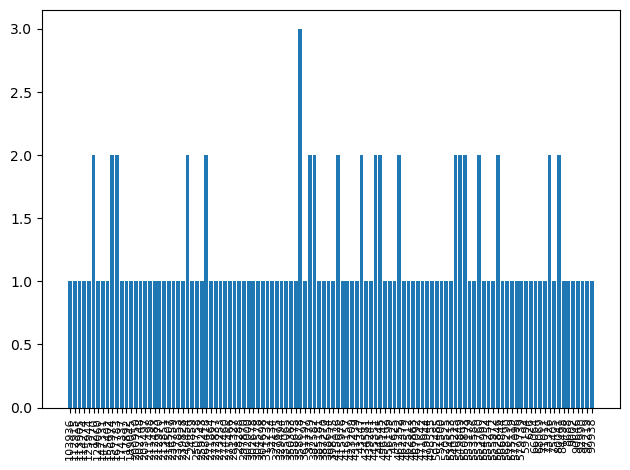

In [ ]:
plt.bar(*np.unique(new_coco_ids, return_counts=True))
plt.xticks(fontsize=8, rotation=90)
plt.tight_layout()
plt.show()


In [ ]:
print("Mode cocoId:", np.unique(new_coco_ids, return_counts=True)[0][np.argmax(np.unique(new_coco_ids, return_counts=True)[1])])


Mode cocoId: 358678


## 4. 저장 결과와 분포 확인

산출물은 `NSD_01_data.npz`다. 저장 위치의 `preprocessed` 폴더는 실행 전에 준비해야 한다.

| 키 | 내용 | 형태 |
|---|---|---|
| `data` | run 내 이미지 ID별 β-map 벡터 | `(133, 292796)` |
| `labels` | 각 벡터에 대응하는 cocoId | `(133,)` |

막대그래프는 저장된 β-map에서 각 이미지 ID가 몇 번 나타나는지 보여준다. 기존 기록에서는 대다수 ID가 1~2회 나타나며 `358678`이 3회로 가장 자주 나타났다. 같은 run의 반복은 GLM에서 합쳐지므로 이 빈도는 원시 이벤트의 자극 제시 횟수와 다를 수 있다.

## 정리

NSD의 이벤트·이미지·캡션을 ID로 연결하고, 원시 BOLD를 이미지 ID별 β-map으로 변환했다. HCP 전처리와 같은 보정 흐름을 사용하면서 GLM의 조건을 시각 자극에 맞게 바꾼 것이 핵심이다.

이 데이터는 후속 캡션 학습에 직접 사용하지 않았다. 별도 제공 β-map으로 학습한 모델에 추가 입력으로 넣은 결과는 04 노트북에서 확인할 수 있다.
